<a href="https://colab.research.google.com/github/earulselvi1998-dev/Coke-Sales-Analysis/blob/main/Chargeability_Review_Sentiment_Analysis_with_Python.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
%pip -q install textblob


In [3]:
import re
import warnings
from collections import Counter
from urllib.error import URLError

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from textblob import TextBlob
from sklearn.feature_extraction.text import CountVectorizer, ENGLISH_STOP_WORDS
from tqdm.auto import tqdm

tqdm.pandas()
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (10, 5)
pd.set_option("display.max_colwidth", 120)


In [4]:
DATA_URL = "https://raw.githubusercontent.com/Ayush-k-Das/ChatGPT_Reviews_Analysis/main/chatgpt_reviews.csv"

try:
    df_raw = pd.read_csv(DATA_URL)
    print("Loaded the public CSV source.")
except Exception as exc:
    print(f"Automatic download failed ({exc}). Upload chatgpt_reviews.csv to continue.")
    from google.colab import files
    uploaded = files.upload()
    csv_name = next((name for name in uploaded if name.lower().endswith(".csv")), None)
    if csv_name is None:
        raise ValueError("Please upload a CSV file.")
    df_raw = pd.read_csv(csv_name)

print(f"Rows: {len(df_raw):,} | Columns: {df_raw.shape[1]}")
display(df_raw.head())
display(df_raw.dtypes.to_frame("data_type"))


Loaded the public CSV source.
Rows: 196,727 | Columns: 4


,Review Id,Review,Ratings,Review Date
0,6fb93778-651a-4ad1-b5ed-67dd0bd35aac,good,5,2024-08-23 19:30:05
1,81caeefd-3a28-4601-a898-72897ac906f5,good,5,2024-08-23 19:28:18
2,452af49e-1d8b-4b68-b1ac-a94c64cb1dd5,nice app,5,2024-08-23 19:22:59
3,372a4096-ee6a-4b94-b046-cef0b646c965,"nice, ig",5,2024-08-23 19:20:50
4,b0d66a4b-9bde-4b7c-8b11-66ed6ccdd7da,"this is a great app, the bot is so accurate to anything, it gives me tips, in gaming, studies, and life, etc. This a...",5,2024-08-23 19:20:39


,data_type
Review Id,object
Review,object
Ratings,int64
Review Date,object


In [5]:
def standardize_column(name):
    name = str(name).strip().lower()
    name = re.sub(r"[^a-z0-9]+", "_", name)
    return name.strip("_")

df = df_raw.copy()
df.columns = [standardize_column(c) for c in df.columns]
print("Standardized columns:", df.columns.tolist())

# Map common source column variants into consistent names.
column_aliases = {
    "review_id": ["review_id", "reviewid", "id"],
    "review": ["review", "review_text", "content"],
    "ratings": ["ratings", "rating", "score"],
    "review_date": ["review_date", "date", "at"],
}
for target, candidates in column_aliases.items():
    if target not in df.columns:
        match = next((c for c in candidates if c in df.columns), None)
        if match is not None:
            df = df.rename(columns={match: target})

required = {"review", "ratings", "review_date"}
missing_required = required - set(df.columns)
if missing_required:
    raise ValueError(f"Missing required columns: {sorted(missing_required)}. Found: {df.columns.tolist()}")

rows_before = len(df)
df = df.drop_duplicates().copy()
print(f"Removed {rows_before - len(df):,} exact duplicate rows; {len(df):,} remain.")

df["review"] = df["review"].fillna("").astype(str).str.strip()
df["ratings"] = pd.to_numeric(df["ratings"], errors="coerce")
df["review_date"] = pd.to_datetime(df["review_date"], errors="coerce", utc=True).dt.tz_convert(None)
df["review_text_present"] = df["review"].str.len().gt(0)
df["review_month"] = df["review_date"].dt.to_period("M").dt.to_timestamp()

print("Missing values after cleaning:")
display(df.isna().sum().to_frame("missing_count"))
print("Non-empty reviews:", f"{df['review_text_present'].sum():,}")
print("Rating range:", df["ratings"].min(), "to", df["ratings"].max())
display(df.head())


Standardized columns: ['review_id', 'review', 'ratings', 'review_date']
Removed 2,511 exact duplicate rows; 194,216 remain.
Missing values after cleaning:


,missing_count
review_id,0
review,0
ratings,0
review_date,0
review_text_present,0
review_month,0


Non-empty reviews: 194,210
Rating range: 1 to 5


,review_id,review,ratings,review_date,review_text_present,review_month
0,6fb93778-651a-4ad1-b5ed-67dd0bd35aac,good,5,2024-08-23 19:30:05,True,2024-08-01
1,81caeefd-3a28-4601-a898-72897ac906f5,good,5,2024-08-23 19:28:18,True,2024-08-01
2,452af49e-1d8b-4b68-b1ac-a94c64cb1dd5,nice app,5,2024-08-23 19:22:59,True,2024-08-01
3,372a4096-ee6a-4b94-b046-cef0b646c965,"nice, ig",5,2024-08-23 19:20:50,True,2024-08-01
4,b0d66a4b-9bde-4b7c-8b11-66ed6ccdd7da,"this is a great app, the bot is so accurate to anything, it gives me tips, in gaming, studies, and life, etc. This a...",5,2024-08-23 19:20:39,True,2024-08-01


Average rating: 4.50 / 5
Median rating: 5.0 / 5


,reviews
rating,
1,11966
2,3346
3,8046
4,22603
5,148255


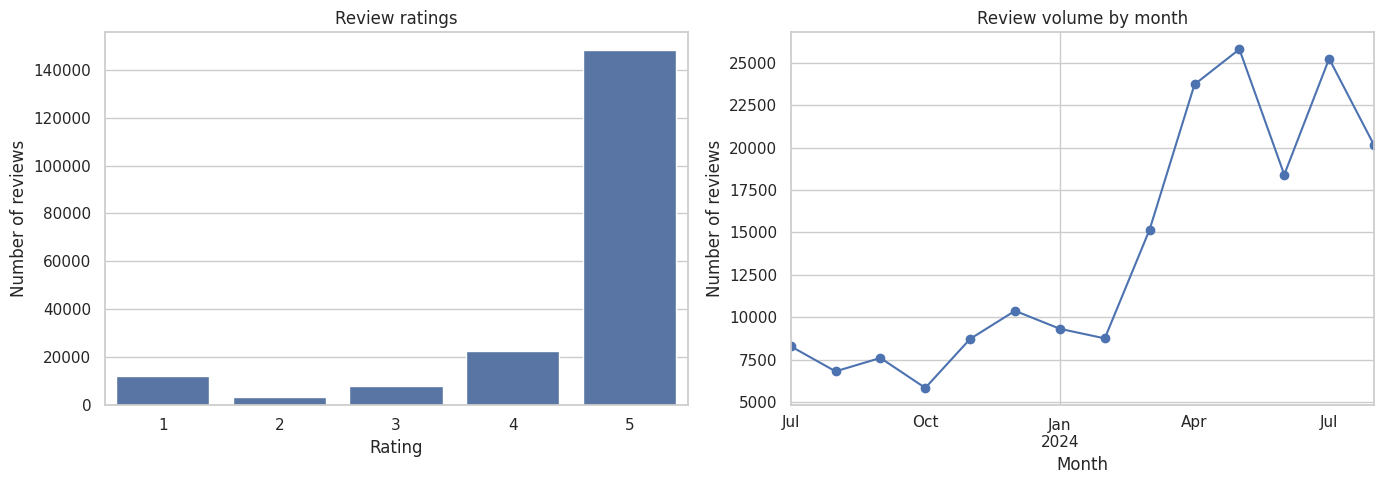

In [6]:
print(f"Average rating: {df['ratings'].mean():.2f} / 5")
print(f"Median rating: {df['ratings'].median():.1f} / 5")
display(df["ratings"].value_counts(dropna=False).sort_index().rename_axis("rating").to_frame("reviews"))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.countplot(data=df, x="ratings", order=sorted(df["ratings"].dropna().unique()), ax=axes[0])
axes[0].set(title="Review ratings", xlabel="Rating", ylabel="Number of reviews")
monthly_counts = df.dropna(subset=["review_month"]).groupby("review_month").size()
monthly_counts.plot(ax=axes[1], marker="o")
axes[1].set(title="Review volume by month", xlabel="Month", ylabel="Number of reviews")
plt.tight_layout()
plt.show()


In [7]:
text_mask = df["review_text_present"]
df["polarity"] = np.nan
df["subjectivity"] = np.nan

def get_polarity(text):
    return TextBlob(text).sentiment.polarity

def get_subjectivity(text):
    return TextBlob(text).sentiment.subjectivity

df.loc[text_mask, "polarity"] = df.loc[text_mask, "review"].progress_apply(get_polarity)
df.loc[text_mask, "subjectivity"] = df.loc[text_mask, "review"].progress_apply(get_subjectivity)

df["sentiment"] = pd.Series(pd.NA, index=df.index, dtype="string")
df.loc[text_mask & (df["polarity"] > 0.05), "sentiment"] = "Positive"
df.loc[text_mask & (df["polarity"] < -0.05), "sentiment"] = "Negative"
df.loc[text_mask & df["polarity"].between(-0.05, 0.05), "sentiment"] = "Neutral"

display(df[["review", "ratings", "polarity", "subjectivity", "sentiment"]].head(10))


  0%|          | 0/194210 [00:00<?, ?it/s]

  0%|          | 0/194210 [00:00<?, ?it/s]

,review,ratings,polarity,subjectivity,sentiment
0,good,5,0.7000,0.600000,Positive
1,good,5,0.7000,0.600000,Positive
2,nice app,5,0.6000,1.000000,Positive
3,"nice, ig",5,0.6000,1.000000,Positive
4,"this is a great app, the bot is so accurate to anything, it gives me tips, in gaming, studies, and life, etc. This a...",5,0.4125,0.542949,Positive
5,so nice app,5,0.6000,1.000000,Positive
6,"just love this app, or guy",4,0.5000,0.600000,Positive
7,great app,1,0.8000,0.750000,Positive
8,Very impressive,5,1.0000,1.000000,Positive
9,helps with coding a lot this ai is great for everyone,5,0.8000,0.750000,Positive


Sentiment counts:


,reviews
sentiment,
Negative,7170
Neutral,40063
Positive,146977


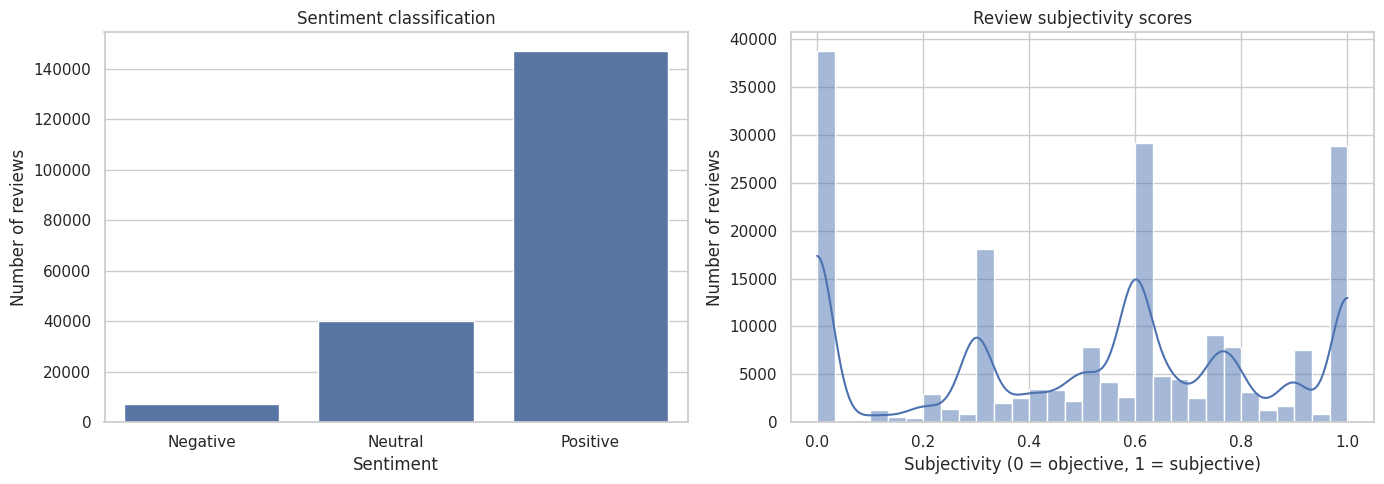

Mean polarity: 0.447
Mean subjectivity: 0.517


In [8]:
sentiment_order = ["Negative", "Neutral", "Positive"]
sentiment_counts = df["sentiment"].value_counts().reindex(sentiment_order, fill_value=0)
print("Sentiment counts:")
display(sentiment_counts.rename_axis("sentiment").to_frame("reviews"))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.barplot(x=sentiment_counts.index, y=sentiment_counts.values, ax=axes[0])
axes[0].set(title="Sentiment classification", xlabel="Sentiment", ylabel="Number of reviews")
sns.histplot(df["subjectivity"].dropna(), bins=30, kde=True, ax=axes[1])
axes[1].set(title="Review subjectivity scores", xlabel="Subjectivity (0 = objective, 1 = subjective)", ylabel="Number of reviews")
plt.tight_layout()
plt.show()

print(f"Mean polarity: {df['polarity'].mean():.3f}")
print(f"Mean subjectivity: {df['subjectivity'].mean():.3f}")


sentiment,Negative,Neutral,Positive
ratings,,,
1,27.8%,43.0%,29.2%
2,18.7%,34.0%,47.3%
3,8.7%,27.3%,64.0%
4,3.2%,19.3%,77.6%
5,1.2%,18.4%,80.4%


,mean,median,count
ratings,,,
1,0.012753,0.000000,11963
2,0.157869,0.000000,3346
3,0.304388,0.258500,8046
4,0.424929,0.437500,22603
5,0.499483,0.539286,148252


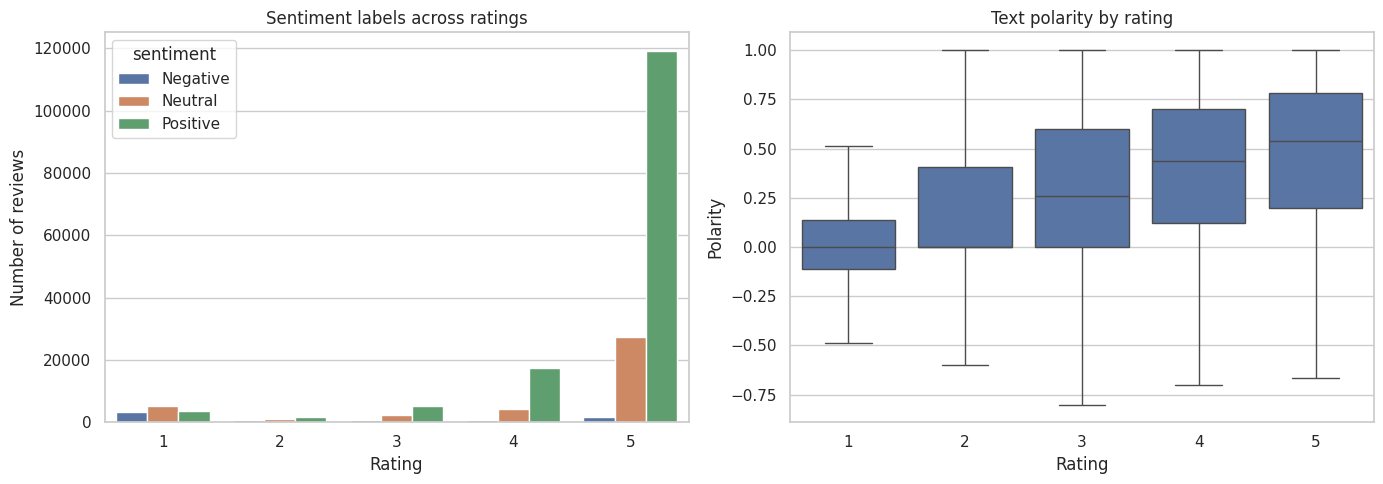

In [9]:
rating_sentiment = pd.crosstab(df["ratings"], df["sentiment"], normalize="index").reindex(columns=sentiment_order)
display(rating_sentiment.style.format("{:.1%}"))

polarity_by_rating = df.groupby("ratings", dropna=True)["polarity"].agg(["mean", "median", "count"])
display(polarity_by_rating)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.countplot(data=df, x="ratings", hue="sentiment", hue_order=sentiment_order, ax=axes[0])
axes[0].set(title="Sentiment labels across ratings", xlabel="Rating", ylabel="Number of reviews")
sns.boxplot(data=df, x="ratings", y="polarity", ax=axes[1], showfliers=False)
axes[1].set(title="Text polarity by rating", xlabel="Rating", ylabel="Polarity")
plt.tight_layout()
plt.show()


Common phrases in positive reviews


,phrase,count
10087,good,38474
3218,best,18073
17852,nice,13577
10910,great,11745
736,ai,9989
11975,helpful,9512
1290,amazing,8519
16124,love,8480
26818,useful,7419
15262,like,6706


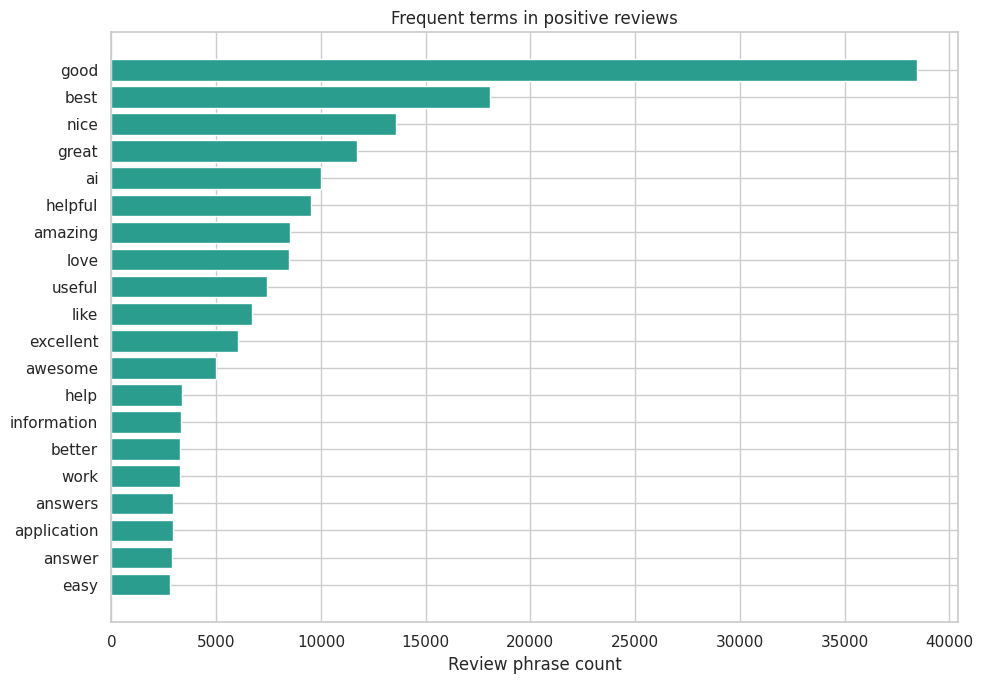

Common phrases in negative reviews


,phrase,count
306,bad,806
3826,wrong,787
87,ai,554
1854,like,513
3336,time,488
165,answer,470
935,don,386
1622,information,360
3791,worst,349
194,answers,348


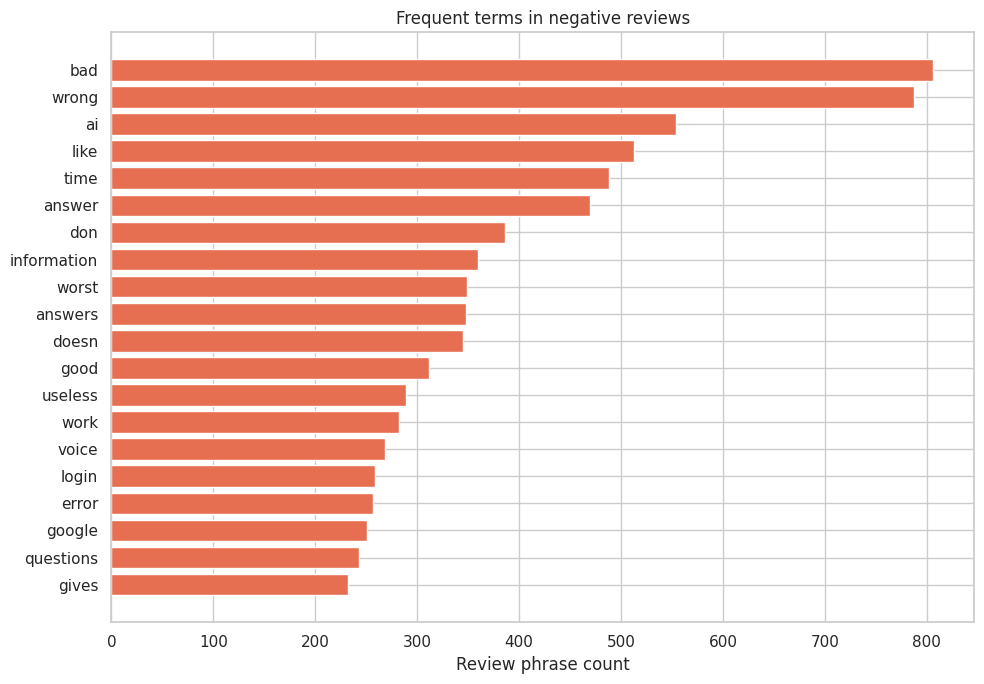

In [10]:
extra_stop_words = {"chatgpt", "chat", "gpt", "app", "use", "using", "used", "ive", "im", "dont", "doesnt", "cant", "couldnt", "would", "really", "just", "one", "get", "got"}
stop_words = sorted(set(ENGLISH_STOP_WORDS).union(extra_stop_words))

def normalize_for_terms(text):
    text = text.lower()
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)
    text = re.sub(r"[^a-z\s]", " ", text)
    return re.sub(r"\s+", " ", text).strip()

def top_phrases(series, n=20):
    texts = series.dropna().map(normalize_for_terms)
    texts = texts[texts.str.len() > 0]
    vectorizer = CountVectorizer(stop_words=stop_words, ngram_range=(1, 2), min_df=3, max_features=30000)
    matrix = vectorizer.fit_transform(texts)
    totals = np.asarray(matrix.sum(axis=0)).ravel()
    result = pd.DataFrame({"phrase": vectorizer.get_feature_names_out(), "count": totals})
    return result.sort_values("count", ascending=False).head(n)

positive_terms = top_phrases(df.loc[df["sentiment"] == "Positive", "review"])
negative_terms = top_phrases(df.loc[df["sentiment"] == "Negative", "review"])

def plot_terms(terms, title, color):
    if terms.empty:
        print(f"No terms available for: {title}")
        return
    plot_data = terms.sort_values("count")
    plt.figure(figsize=(10, 7))
    plt.barh(plot_data["phrase"], plot_data["count"], color=color)
    plt.title(title)
    plt.xlabel("Review phrase count")
    plt.ylabel("")
    plt.tight_layout()
    plt.show()

print("Common phrases in positive reviews")
display(positive_terms.head(15))
plot_terms(positive_terms, "Frequent terms in positive reviews", "#2a9d8f")

print("Common phrases in negative reviews")
display(negative_terms.head(15))
plot_terms(negative_terms, "Frequent terms in negative reviews", "#e76f51")


,review_month,review_count,mean_polarity,mean_rating
0,2023-07-01,8283,0.369545,4.439454
1,2023-08-01,6801,0.385239,4.327746
2,2023-09-01,7593,0.424308,4.494534
3,2023-10-01,5824,0.433077,4.525755
4,2023-11-01,8719,0.428241,4.523913


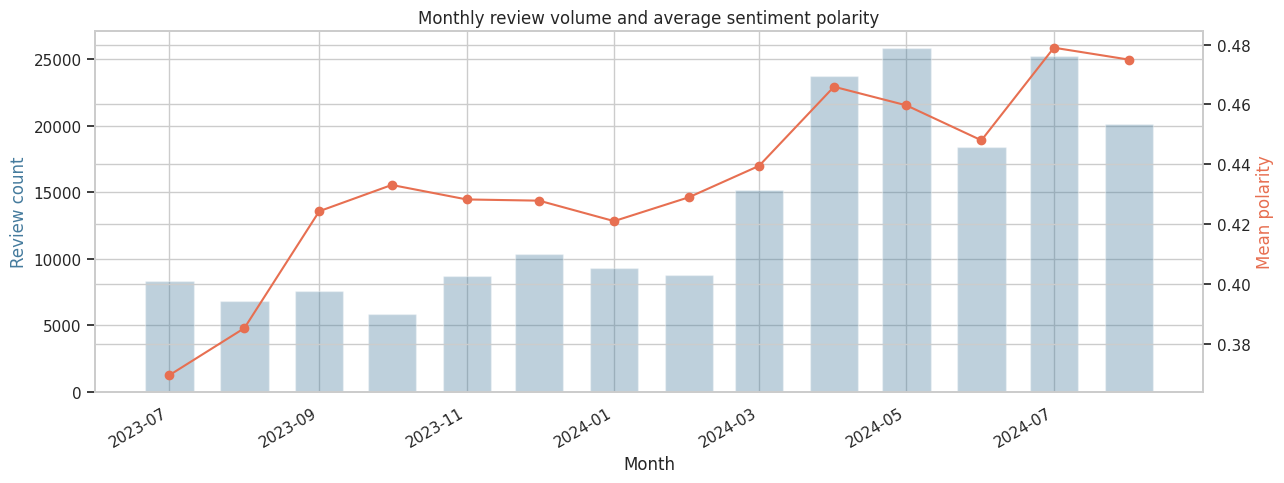

In [11]:
monthly = (
    df.dropna(subset=["review_month"])
      .groupby("review_month")
      .agg(review_count=("review", "size"), mean_polarity=("polarity", "mean"), mean_rating=("ratings", "mean"))
      .reset_index()
)
display(monthly.head())

fig, ax1 = plt.subplots(figsize=(13, 5))
ax1.bar(monthly["review_month"], monthly["review_count"], width=20, alpha=0.35, color="#457b9d")
ax1.set_xlabel("Month")
ax1.set_ylabel("Review count", color="#457b9d")
ax2 = ax1.twinx()
ax2.plot(monthly["review_month"], monthly["mean_polarity"], marker="o", color="#e76f51", label="Mean polarity")
ax2.set_ylabel("Mean polarity", color="#e76f51")
ax1.set_title("Monthly review volume and average sentiment polarity")
fig.autofmt_xdate()
plt.tight_layout()
plt.show()


,aspect,reviews_mentioning_aspect,share_of_scored_reviews,mean_polarity,negative_share,positive_share
1,Usefulness and productivity,25716,13.2%,0.326,2.7%,84.9%
0,Accuracy and answer quality,8015,4.1%,0.265,13.9%,72.5%
4,Features and access,7566,3.9%,0.211,12.2%,61.8%
2,Ease of use and interface,4671,2.4%,0.370,2.4%,91.4%
3,Speed and reliability,3081,1.6%,0.269,11.3%,78.5%


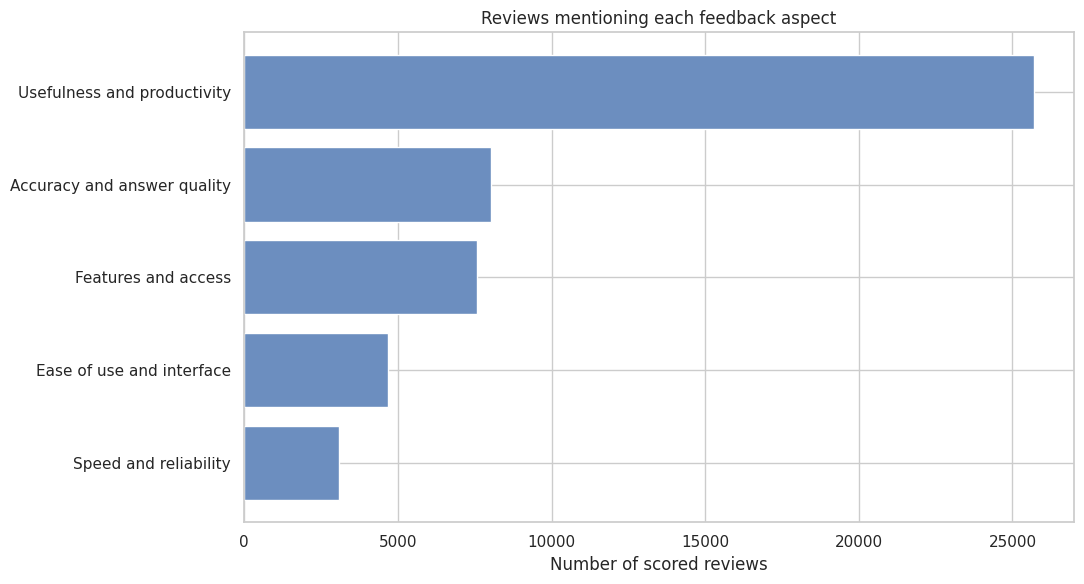

In [12]:
aspect_keywords = {
    "Accuracy and answer quality": ["accurate", "accuracy", "wrong", "incorrect", "hallucinat", "answer", "response", "fact", "mistake"],
    "Usefulness and productivity": ["helpful", "useful", "productive", "work", "write", "writing", "research", "learn", "study"],
    "Ease of use and interface": ["easy", "simple", "interface", "design", "ui", "navigation", "user friendly"],
    "Speed and reliability": ["slow", "fast", "crash", "loading", "bug", "glitch", "freeze", "performance"],
    "Features and access": ["feature", "voice", "image", "upload", "limit", "subscription", "login", "sign in", "update"],
}

review_lower = df["review"].str.lower()
for aspect, words in aspect_keywords.items():
    pattern = r"\b(?:" + "|".join(re.escape(w) for w in sorted(words, key=len, reverse=True)) + r")\b"
    df[aspect] = review_lower.str.contains(pattern, regex=True, na=False)

aspect_rows = []
for aspect in aspect_keywords:
    matched = df[df[aspect] & df["sentiment"].notna()]
    aspect_rows.append({
        "aspect": aspect,
        "reviews_mentioning_aspect": len(matched),
        "share_of_scored_reviews": len(matched) / max(df["sentiment"].notna().sum(), 1),
        "mean_polarity": matched["polarity"].mean(),
        "negative_share": (matched["sentiment"] == "Negative").mean(),
        "positive_share": (matched["sentiment"] == "Positive").mean(),
    })
aspect_summary = pd.DataFrame(aspect_rows).sort_values("reviews_mentioning_aspect", ascending=False)
display(aspect_summary.style.format({"share_of_scored_reviews":"{:.1%}", "mean_polarity":"{:.3f}", "negative_share":"{:.1%}", "positive_share":"{:.1%}"}))

plt.figure(figsize=(11, 6))
plot_data = aspect_summary.sort_values("reviews_mentioning_aspect")
plt.barh(plot_data["aspect"], plot_data["reviews_mentioning_aspect"], color="#6c8ebf")
plt.title("Reviews mentioning each feedback aspect")
plt.xlabel("Number of scored reviews")
plt.tight_layout()
plt.show()


In [13]:
valid_scores = df.dropna(subset=["polarity", "ratings"])
print("ANALYSIS SUMMARY")
print("=" * 60)
print(f"Rows after exact duplicate removal: {len(df):,}")
print(f"Non-empty reviews scored: {df['polarity'].notna().sum():,}")
print(f"Average star rating: {df['ratings'].mean():.2f} / 5")
print(f"Average TextBlob polarity: {df['polarity'].mean():.3f}")
print(f"Average subjectivity: {df['subjectivity'].mean():.3f}")
print("Sentiment shares:")
print((df["sentiment"].value_counts(normalize=True).reindex(sentiment_order, fill_value=0) * 100).round(1).astype(str) + "%")
if not monthly.empty:
    print(f"Month with most reviews: {monthly.loc[monthly['review_count'].idxmax(), 'review_month']:%Y-%m}")
if not positive_terms.empty:
    print("Most common positive phrase:", positive_terms.iloc[0]["phrase"])
if not negative_terms.empty:
    print("Most common negative phrase:", negative_terms.iloc[0]["phrase"])
print("\nReview text is user-generated and may contain sarcasm, typos, or context that lexicon methods do not capture.")


ANALYSIS SUMMARY
Rows after exact duplicate removal: 194,216
Non-empty reviews scored: 194,210
Average star rating: 4.50 / 5
Average TextBlob polarity: 0.447
Average subjectivity: 0.517
Sentiment shares:
sentiment
Negative     3.7%
Neutral     20.6%
Positive    75.7%
Name: proportion, dtype: object
Month with most reviews: 2024-05
Most common positive phrase: good
Most common negative phrase: bad

Review text is user-generated and may contain sarcasm, typos, or context that lexicon methods do not capture.


In [14]:
def show_examples(label, n=5):
    sample = df.loc[df["sentiment"] == label, [c for c in ["review_id", "ratings", "review_date", "polarity", "review"] if c in df.columns]]
    return sample.sample(min(n, len(sample)), random_state=42) if len(sample) else sample

display(show_examples("Positive"))
display(show_examples("Negative"))


,review_id,ratings,review_date,polarity,review
2791,0c783486-5953-4371-b1da-f9d8edfb0b6d,5,2024-08-21 08:01:00,1.000000,the best of all
57576,3d4ce1b5-a899-4407-8961-5e4a871c7c30,5,2024-06-12 01:50:44,0.600000,Nice ChatGPT
100188,444bd55e-4194-4498-80c8-a6e2a4c8600c,5,2023-08-07 08:02:13,0.459524,"Suprisingly great app. ChatGPT is great as usual, but the app provides a nice and clean interface to interact with i..."
20565,7ff4de77-1c03-4b10-ac6c-049c47e40c1a,5,2024-07-31 11:52:53,0.200000,very helpful app for students
113325,3541666c-19d5-4a2f-88d9-3ab88911b885,4,2024-04-04 06:27:55,0.500000,personally it is good and useful


,review_id,ratings,review_date,polarity,review
76700,62607191-ba43-4b36-9dca-ddb7fe1be75e,4,2024-05-19 10:44:10,-0.600000,crazy
110544,8d773e20-7730-4ba6-b96c-3289428117ab,5,2024-03-31 06:49:23,-0.200000,"this is the game changer, our future"
109138,4c874009-1eab-4c42-b865-09cc821a46b4,2,2023-07-26 14:16:34,-0.145000,Search any content writing type result is very slow not convenient to use But use Google bard show direct result. So...
86833,56d61e16-3fc3-4cdd-ba52-9807cad5133b,1,2024-03-24 19:24:27,-0.238889,This one just confused with my calculations. try to make betterone. Calculations failure. It can either think of cal...
115929,28f40b23-2aec-4254-bfa1-32f3b648b525,4,2024-03-31 09:19:33,-0.250000,you must know the past things also which are manufactured before you.😅
